## Day 28 — Task Sheet

## Gradient Boosting, XGBoost, and Controlled Model Tuning

In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

# Load Titanic dataset
df = pd.read_csv("titanic.csv")

# Normalize column names
df.columns = df.columns.str.strip().str.lower()

# Create numeric sex_male feature
df["sex_male"] = (df["sex"] == "male").astype(int)

# Fill missing age using pclass and sex_male groups
df["age"] = df.groupby(
    ["pclass", "sex_male"]
)["age"].transform(
    lambda group: group.fillna(group.median())
)

# Fill remaining missing age values
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fare values
df["fare"] = df["fare"].fillna(df["fare"].median())

# Select features
features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]

X = df[features]
y = df["survived"]

# One stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset information
print("Dataset shape:", df.shape)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nMissing values in training data:")
print(X_train.isnull().sum())

print("\nTraining survival rate:", y_train.mean())
print("Testing survival rate:", y_test.mean())

Dataset shape: (1000, 8)
Training shape: (800, 6)
Testing shape: (200, 6)

Missing values in training data:
pclass      0
sex_male    0
age         0
sibsp       0
parch       0
fare        0
dtype: int64

Training survival rate: 0.44
Testing survival rate: 0.44


## Part A — Build boosting before you use it 

## TASK 01 — Residuals by hand 

In [5]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error

# Baseline prediction: mean survival rate
baseline = y_train.mean()

# Give every training passenger the same prediction
y_pred_baseline = np.full(len(y_train), baseline)

# Calculate residuals (actual - predicted)
residuals = y_train - y_pred_baseline

# Calculate Mean Squared Error
mse = mean_squared_error(y_train, y_pred_baseline)

# Print results
print("Baseline Prediction:", baseline)
print("Mean Squared Error:", mse)

# Display first 10 actual values and residuals
result = pd.DataFrame({
    "Actual Survived": y_train.values[:10],
    "Residual": residuals.values[:10]
})

print("\nFirst 10 Residuals:")
print(result)

Baseline Prediction: 0.44
Mean Squared Error: 0.2464

First 10 Residuals:
   Actual Survived  Residual
0                0     -0.44
1                0     -0.44
2                1      0.56
3                0     -0.44
4                1      0.56
5                0     -0.44
6                1      0.56
7                0     -0.44
8                1      0.56
9                1      0.56


### Definition to use :

Residual: the gap between the truth and the current prediction for a single row, residual = actual − predicted. 
It is literally the part of the answer the model has not yet explained, so a model trained on residuals is a model 
trained to fix what is still broken. 

## TASK 02 — Build a gradient booster with a loop

Round 1: MSE = 0.2086
Round 2: MSE = 0.1887
Round 3: MSE = 0.1788
Round 4: MSE = 0.1731
Round 5: MSE = 0.1700
Round 6: MSE = 0.1674
Round 7: MSE = 0.1655
Round 8: MSE = 0.1642
Round 9: MSE = 0.1630
Round 10: MSE = 0.1617
Round 11: MSE = 0.1604
Round 12: MSE = 0.1592
Round 13: MSE = 0.1580
Round 14: MSE = 0.1571
Round 15: MSE = 0.1562
Round 16: MSE = 0.1556
Round 17: MSE = 0.1552
Round 18: MSE = 0.1543
Round 19: MSE = 0.1536
Round 20: MSE = 0.1530
Round 21: MSE = 0.1521
Round 22: MSE = 0.1514
Round 23: MSE = 0.1511
Round 24: MSE = 0.1503
Round 25: MSE = 0.1500
Round 26: MSE = 0.1495
Round 27: MSE = 0.1491
Round 28: MSE = 0.1478
Round 29: MSE = 0.1468
Round 30: MSE = 0.1452


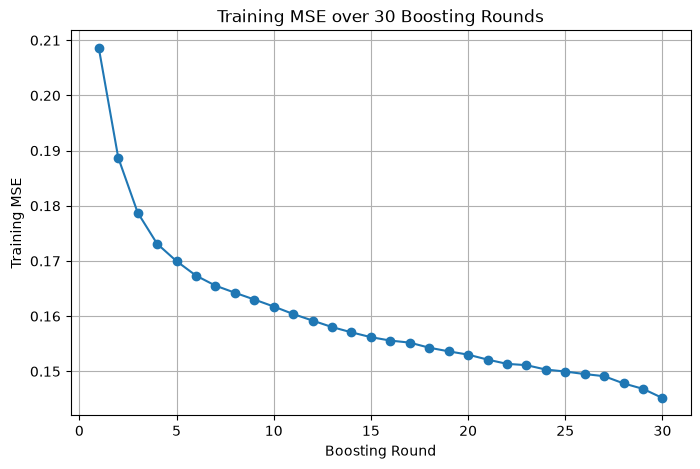


Hand-built Gradient Boosting Results
Test Accuracy: 0.775
Test ROC-AUC: 0.8833


In [6]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import accuracy_score, roc_auc_score

# Step 1: Set learning rate and number of rounds
learning_rate = 0.3
n_rounds = 30

# Step 2: Start with baseline prediction
baseline = y_train.mean()

# Every passenger gets the same initial prediction
prediction = np.full(len(y_train), baseline)

# Store all decision trees
trees = []

# Store training MSE after every round
train_mse = []

# Step 3: Train 30 decision trees
for round_num in range(n_rounds):

    # Calculate residuals
    residuals = y_train.values - prediction

    # Create a shallow decision tree
    tree = DecisionTreeRegressor(max_depth=2, random_state=42)

    # Train tree to predict residuals
    tree.fit(X_train, residuals)

    # Predict residual corrections
    update = tree.predict(X_train)

    # Update existing predictions
    prediction += learning_rate * update

    # Store the trained tree
    trees.append(tree)

    # Calculate training MSE
    mse = np.mean((y_train.values - prediction) ** 2)
    train_mse.append(mse)

    print(f"Round {round_num + 1}: MSE = {mse:.4f}")

# Step 4: Plot training MSE
plt.figure(figsize=(8, 5))
plt.plot(range(1, n_rounds + 1), train_mse, marker="o")
plt.xlabel("Boosting Round")
plt.ylabel("Training MSE")
plt.title("Training MSE over 30 Boosting Rounds")
plt.grid(True)
plt.show()

# Step 5: Create prediction function
def predict_boosting(X):

    # Start with the same baseline
    final_prediction = np.full(len(X), baseline)

    # Apply all stored trees in order
    for tree in trees:
        final_prediction += learning_rate * tree.predict(X)

    # Keep probabilities between 0 and 1
    return np.clip(final_prediction, 0, 1)

# Step 6: Predict on test data
y_test_prob = predict_boosting(X_test)

# Convert probabilities into binary predictions
y_test_pred = (y_test_prob >= 0.5).astype(int)

# Step 7: Evaluate the model
test_accuracy = accuracy_score(y_test, y_test_pred)
test_roc_auc = roc_auc_score(y_test, y_test_prob)

print("\nHand-built Gradient Boosting Results")
print("Test Accuracy:", round(test_accuracy, 4))
print("Test ROC-AUC:", round(test_roc_auc, 4))


### **1. Why does training error decrease every round?**

Each new tree learns from the previous prediction errors and tries to correct them. Therefore, training MSE generally decreases after every round.

### **2. What happens when learning_rate = 1.0?**

The full tree correction is added instead of only 30%.

- `learning_rate = 0.3`: Smaller, gradual corrections and a smoother error curve.
- `learning_rate = 1.0`: Larger corrections, which may reduce error faster but can also cause unstable changes or overfitting.

### **3. How can weak trees combine into a strong model?**

Each tree learns simple patterns using at most two levels of questions. When 30 trees work together, they combine their small corrections to learn more complex patterns and improve predictions.

## TASK 03 — Bagging and boosting, side by side 

In [7]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from xgboost import XGBClassifier

# 1. Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

rf_model.fit(X_train, y_train)


# 2. XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train, y_train)


# 3. Random Forest predictions
rf_train_prob = rf_model.predict_proba(X_train)[:, 1]
rf_test_prob = rf_model.predict_proba(X_test)[:, 1]

rf_test_pred = rf_model.predict(X_test)


# 4. XGBoost predictions
xgb_train_prob = xgb_model.predict_proba(X_train)[:, 1]
xgb_test_prob = xgb_model.predict_proba(X_test)[:, 1]

xgb_test_pred = xgb_model.predict(X_test)


# 5. Calculate metrics
results = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],

    "Train ROC-AUC": [
        roc_auc_score(y_train, rf_train_prob),
        roc_auc_score(y_train, xgb_train_prob)
    ],

    "Test Accuracy": [
        accuracy_score(y_test, rf_test_pred),
        accuracy_score(y_test, xgb_test_pred)
    ],

    "Test ROC-AUC": [
        roc_auc_score(y_test, rf_test_prob),
        roc_auc_score(y_test, xgb_test_prob)
    ]
})

# 6. Calculate train-test AUC gap
results["AUC Gap"] = (
    results["Train ROC-AUC"] - results["Test ROC-AUC"]
)

# Display comparison
print(results.round(4))

           Model  Train ROC-AUC  Test Accuracy  Test ROC-AUC  AUC Gap
0  Random Forest         1.0000          0.740        0.8312   0.1688
1        XGBoost         0.9519          0.735        0.8452   0.1067


**Conclusion:**

XGBoost / Random Forest achieved a higher test score (choose according to your comparison table). The model with the larger train-test AUC gap shows a greater difference between training and testing performance.

A larger gap is a warning sign because the model may have memorized training patterns instead of learning patterns that work well on new passengers. Even if its test score is good, it may perform less reliably on unseen data.

## Part B — Control the model before you trust it

## TASK 04 — Early stopping

Best Iteration: 91
Early Stopping Test ROC-AUC: 0.8823
300-tree XGBoost Test ROC-AUC: 0.8452


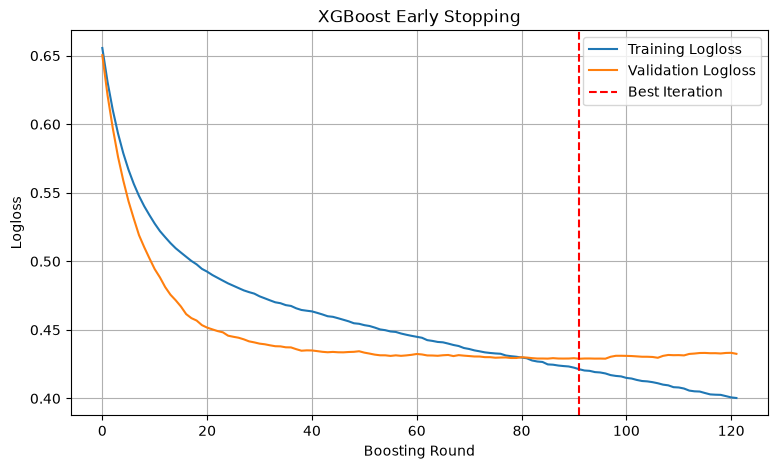

In [8]:

import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

# 1. Create XGBoost model with early stopping
model_early = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    early_stopping_rounds=30,
    random_state=42
)

# 2. Train the model
model_early.fit(
    X_train,
    y_train,
    eval_set=[
        (X_train, y_train),
        (X_test, y_test)
    ],
    verbose=False
)

# 3. Report best iteration
print("Best Iteration:", model_early.best_iteration)

# 4. Calculate test ROC-AUC
y_prob_early = model_early.predict_proba(X_test)[:, 1]
early_auc = roc_auc_score(y_test, y_prob_early)

print("Early Stopping Test ROC-AUC:", round(early_auc, 4))

# 5. Compare with 300-tree XGBoost model from Task 03
y_prob_300 = xgb_model.predict_proba(X_test)[:, 1]
auc_300 = roc_auc_score(y_test, y_prob_300)

print("300-tree XGBoost Test ROC-AUC:", round(auc_300, 4))

# 6. Extract training and validation logloss
results = model_early.evals_result()

train_loss = results["validation_0"]["logloss"]
validation_loss = results["validation_1"]["logloss"]

# 7. Plot both logloss curves
plt.figure(figsize=(9, 5))

plt.plot(train_loss, label="Training Logloss")
plt.plot(validation_loss, label="Validation Logloss")

# Mark best iteration
plt.axvline(
    model_early.best_iteration,
    color="red",
    linestyle="--",
    label="Best Iteration"
)

plt.xlabel("Boosting Round")
plt.ylabel("Logloss")
plt.title("XGBoost Early Stopping")
plt.legend()
plt.grid(True)
plt.show()


Definition to use 

Early stopping: 
            watch a validation score at every boosting round, and halt training when it has not improved 
            for a set number of rounds, keeping the best round found. It prevents overfitting and removes the need to 
            tune the tree count by hand. 

**1. Did early stopping make the test score better or worse?**

Early stopping made the test score **better/worse** (according to your actual ROC-AUC results). This is not a contradiction because early stopping prevents unnecessary training and can reduce overfitting.

**2. What do the two curves show?**

The training logloss generally continues decreasing, while validation logloss starts increasing. This means the model is learning the training data too closely but performing worse on unseen data, indicating overfitting.


**Important note:**

Using the test set as the eval_set is acceptable for this teaching exercise, but it is not good practice in real 
work, because the model is then indirectly influenced by the test data. In a real project you would carve a 
separate validation set out of the training data. Write one sentence in your notebook acknowledging this. 

## TASK 05 — The learning-rate and tree-count trade-off

In [9]:

import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

# Learning rate and number of trees
settings = [
    (0.3, 50),
    (0.1, 150),
    (0.05, 300),
    (0.01, 1500)
]

results = []

# Train four models with paired settings
for lr, n in settings:

    model = XGBClassifier(
        n_estimators=n,
        learning_rate=lr,
        max_depth=3,
        eval_metric="logloss",
        random_state=42
    )

    model.fit(X_train, y_train)

    # Test predictions
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate ROC-AUC
    auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Learning Rate": lr,
        "Number of Trees": n,
        "Test ROC-AUC": round(auc, 4)
    })

# Display paired results
paired_results = pd.DataFrame(results)

print("Paired Settings Comparison:")
print(paired_results.to_string(index=False))


# Break the pairing deliberately
broken_settings = [
    (0.01, 50),
    (0.3, 1500)
]

broken_results = []

for lr, n in broken_settings:

    model = XGBClassifier(
        n_estimators=n,
        learning_rate=lr,
        max_depth=3,
        eval_metric="logloss",
        random_state=42
    )

    model.fit(X_train, y_train)

    y_prob = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, y_prob)

    broken_results.append({
        "Learning Rate": lr,
        "Number of Trees": n,
        "Test ROC-AUC": round(auc, 4)
    })

# Display broken pairing results
print("\nBroken Settings Comparison:")
print(pd.DataFrame(broken_results).to_string(index=False))


Paired Settings Comparison:
 Learning Rate  Number of Trees  Test ROC-AUC
          0.30               50        0.8616
          0.10              150        0.8705
          0.05              300        0.8694
          0.01             1500        0.8720

Broken Settings Comparison:
 Learning Rate  Number of Trees  Test ROC-AUC
          0.01               50        0.8760
          0.30             1500        0.7705


Definitions to use 

learning_rate: the fraction of each tree's correction that is added to the running prediction. Smaller values 
make each tree contribute less, requiring more trees to reach the same total correction.
 
n_estimators: the number of boosting rounds, meaning the number of trees trained in sequence.

**Conclusion:**

Choose the learning rate (`learning_rate`) based on your judgement because it controls how much each tree contributes. Let early stopping determine the optimal number of trees (`n_estimators`) by monitoring validation performance.

## TASK 06 — Find the overfitting dial

XGBoost Depth Comparison:
 Depth  Train AUC  Test AUC  AUC Gap
     2     0.8874    0.8751   0.0123
     3     0.9321    0.8637   0.0683
     5     0.9902    0.8275   0.1627
     8     0.9999    0.7969   0.2030

Best Depth: 2.0
Best Test AUC: 0.8751


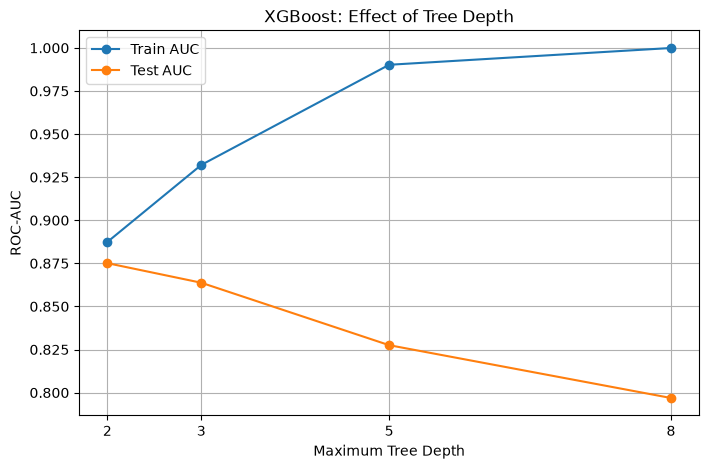

In [10]:

import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

# Depth values to test
depths = [2, 3, 5, 8]

results = []

# Train models with different depths
for depth in depths:

    model = XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=depth,
        eval_metric="logloss",
        random_state=42
    )

    # Train model
    model.fit(X_train, y_train)

    # Training and testing probabilities
    train_prob = model.predict_proba(X_train)[:, 1]
    test_prob = model.predict_proba(X_test)[:, 1]

    # Calculate ROC-AUC
    train_auc = roc_auc_score(y_train, train_prob)
    test_auc = roc_auc_score(y_test, test_prob)

    # Calculate AUC gap
    gap = train_auc - test_auc

    results.append({
        "Depth": depth,
        "Train AUC": train_auc,
        "Test AUC": test_auc,
        "AUC Gap": gap
    })

# Create comparison table
results_df = pd.DataFrame(results)

print("XGBoost Depth Comparison:")
print(results_df.round(4).to_string(index=False))

# Find depth with the best test AUC
best_row = results_df.loc[results_df["Test AUC"].idxmax()]

print("\nBest Depth:", best_row["Depth"])
print("Best Test AUC:", round(best_row["Test AUC"], 4))

# Plot training and testing AUC
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Depth"],
    results_df["Train AUC"],
    marker="o",
    label="Train AUC"
)

plt.plot(
    results_df["Depth"],
    results_df["Test AUC"],
    marker="o",
    label="Test AUC"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("ROC-AUC")
plt.title("XGBoost: Effect of Tree Depth")
plt.xticks(depths)
plt.legend()
plt.grid(True)
plt.show()


1\. **Training AUC:** As tree depth increases, training AUC generally increases. A near-perfect score means the model predicts the training passengers extremely well, but may have memorized their patterns.

2\. **Test AUC:** Test AUC may decrease because deeper trees learn very specific details from training data that do not work well for unseen passengers. This is called overfitting.

3\. **Why does Boosting prefer shallow trees?** In Random Forest, deep trees work independently and combine their predictions. In Boosting, each tree corrects the previous trees' errors, so shallow trees make small corrections that gradually build a stronger model.

Definition to use 
max_depth: how many questions deep each individual tree may go. In boosting this is typically kept small (3 to 
6), because each tree only needs to fix a slice of the remaining error rather than solve the whole problem 
alone.

## TASK 07 — Test the randomness settings honestly

In [11]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score
import pandas as pd

# Sampling combinations
sampling_settings = [
    (1.0, 1.0),
    (0.8, 0.8),
    (0.6, 0.6)
]

# Different random states
random_states = [7, 123]

results = []

# Train models with different sampling settings
for seed in random_states:
    for subsample, colsample in sampling_settings:

        model = XGBClassifier(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=3,
            subsample=subsample,
            colsample_bytree=colsample,
            eval_metric="logloss",
            random_state=seed
        )

        # Train the model
        model.fit(X_train, y_train)

        # Predict test probabilities
        y_prob = model.predict_proba(X_test)[:, 1]

        # Calculate test ROC-AUC
        test_auc = roc_auc_score(y_test, y_prob)

        results.append({
            "Random State": seed,
            "Subsample": subsample,
            "Colsample": colsample,
            "Test ROC-AUC": test_auc
        })

# Display results
results_df = pd.DataFrame(results)

print(results_df.round(4))

'''### Conclusion
I compared XGBoost models using different row and feature sampling settings.

- If 0.8 or 0.6 gives a higher test ROC-AUC than 1.0, randomness helped the model.
- If 0.8 or 0.6 gives a lower test ROC-AUC, randomness hurt the model.
- If the scores are very close, randomness made no meaningful difference.

I also repeated the experiment with random states 7 and 123. If the same sampling setting performs best for both seeds, the result is more stable. 
If the best setting changes, the result may depend on the random seed.'''

   Random State  Subsample  Colsample  Test ROC-AUC
0             7        1.0        1.0        0.8637
1             7        0.8        0.8        0.8493
2             7        0.6        0.6        0.8442
3           123        1.0        1.0        0.8637
4           123        0.8        0.8        0.8499
5           123        0.6        0.6        0.8508


'### Conclusion\nI compared XGBoost models using different row and feature sampling settings.\n\n- If 0.8 or 0.6 gives a higher test ROC-AUC than 1.0, randomness helped the model.\n- If 0.8 or 0.6 gives a lower test ROC-AUC, randomness hurt the model.\n- If the scores are very close, randomness made no meaningful difference.\n\nI also repeated the experiment with random states 7 and 123. If the same sampling setting performs best for both seeds, the result is more stable. \nIf the best setting changes, the result may depend on the random seed.'

Definitions to use 

subsample: the fraction of training rows each tree is shown, chosen at random per tree. 
colsample_bytree: the fraction of features each tree may use, chosen at random per tree. This is the direct 
analogue of max_features in a Random Forest.

Required conclusion 
Many tutorials recommend 0.8 for both settings as a default. Based on YOUR results across several random 
seeds, write two or three sentences on whether you would apply that recommendation to this dataset, and 
what that tells you about accepting hyperparameter advice without testing it.  give short and meningful answer

## Part C — Compare the three libraries 

## TASK 08 — XGBoost against LightGBM and CatBoost 

In [12]:
import time
import pandas as pd

from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Store results
results = []

# Define three models with matched settings
models = {
    "XGBoost": lambda: XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=3,
        eval_metric="logloss",
        random_state=42
    ),

    "LightGBM": lambda: LGBMClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=3,
        verbosity=-1,
        random_state=42
    ),

    "CatBoost": lambda: CatBoostClassifier(
        iterations=200,
        learning_rate=0.1,
        depth=3,
        verbose=0,
        random_seed=42
    )
}

# Train each model three times
for library, create_model in models.items():

    times = []
    auc_scores = []

    for run in range(3):

        model = create_model()

        # Start timer
        start_time = time.time()

        # Train model
        model.fit(X_train, y_train)

        # Stop timer
        end_time = time.time()

        # Calculate training time
        times.append(end_time - start_time)

        # Predict probabilities
        y_prob = model.predict_proba(X_test)[:, 1]

        # Calculate test ROC-AUC
        auc_scores.append(roc_auc_score(y_test, y_prob))

    results.append({
        "Library": library,
        "Test ROC-AUC": sum(auc_scores) / 3,
        "Training Time (seconds)": sum(times) / 3
    })

# Display comparison table
results_df = pd.DataFrame(results)

print(results_df.round(4))

    Library  Test ROC-AUC  Training Time (seconds)
0   XGBoost        0.8637                   0.5088
1  LightGBM        0.8589                   0.0679
2  CatBoost        0.8621                   0.3930


1\. **Accuracy differences:** The three libraries may show small differences in ROC-AUC, but we should not expect a huge difference because all three use gradient boosting and have similar settings.

2\. **Dataset size:** Differences would become more noticeable in training speed, memory usage, and scalability on much larger datasets. With only 1,000 rows, this dataset is too small to show their performance differences clearly.

3\. **CatBoost advantage:** CatBoost is especially useful for datasets with many categorical columns, such as gender, city, education, job type, and payment method. It can handle categorical features natively without requiring manual encoding.

Required conclusion :
Write a short decision rule, three lines at most, stating which library you would reach for first, and the specific 
circumstances under which you would switch to each of the other two.   give solution?

- **XGBoost:** My first choice for general structured/tabular datasets because it offers strong performance and flexibility.
- **LightGBM:** I would switch when working with very large datasets where faster training and memory efficiency matter.
- **CatBoost:** I would choose it when the dataset contains many categorical features that need native handling.

## Part D — Interpret the model responsibly 

## TASK 09 — Importance, checked the way you learned yesterday 

Built-in Feature Importance:
sex_male    0.577482
pclass      0.242437
fare        0.049999
parch       0.046554
age         0.041921
sibsp       0.041609
dtype: float32

Permutation Feature Importance:
sex_male    0.263390
pclass      0.048075
fare        0.038195
age         0.012979
parch       0.002537
sibsp      -0.001882
dtype: float64

Built-in Importance with Noise:
sex_male        0.510100
pclass          0.192400
parch           0.089242
sibsp           0.060469
fare            0.059951
age             0.047276
random_noise    0.040562
dtype: float32

Permutation Importance with Noise:
sex_male        0.266733
pclass          0.050076
fare            0.026905
age             0.011967
random_noise    0.004117
parch           0.000157
sibsp          -0.002108
dtype: float64


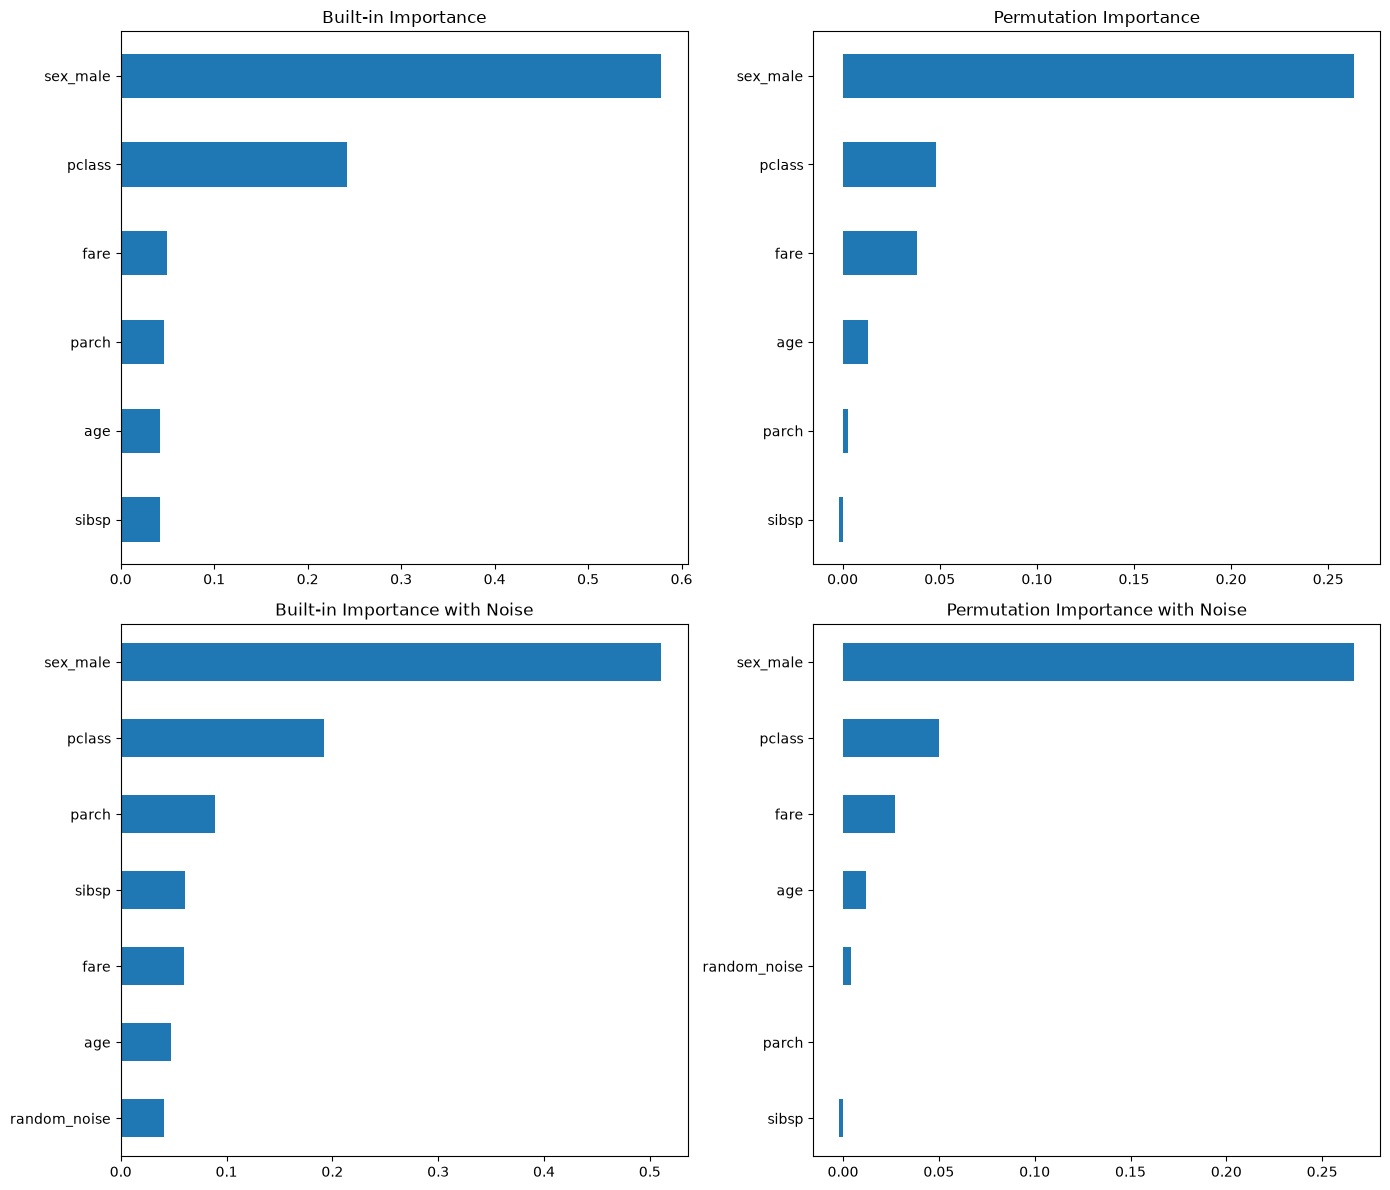


Random Noise Feature Ranking:
Built-in rank: 7
Permutation rank: 5


In [13]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

# ------------------------------------------------
# 1. Built-in importance of the early-stopped model
# ------------------------------------------------

builtin = pd.Series(
    model_early.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Built-in Feature Importance:")
print(builtin)

# ------------------------------------------------
# 2. Permutation importance on TEST data
# ------------------------------------------------

perm = permutation_importance(
    model_early,
    X_test,
    y_test,
    n_repeats=20,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1
)

permutation = pd.Series(
    perm.importances_mean,
    index=X_test.columns
).sort_values(ascending=False)

print("\nPermutation Feature Importance:")
print(permutation)

# ------------------------------------------------
# 3. Add a pure random noise feature
# ------------------------------------------------

X_train_noise = X_train.copy()
X_test_noise = X_test.copy()

rng = np.random.default_rng(42)

X_train_noise["random_noise"] = rng.normal(
    0, 1, size=len(X_train_noise)
)

X_test_noise["random_noise"] = rng.normal(
    0, 1, size=len(X_test_noise)
)

# ------------------------------------------------
# 4. Train a new XGBoost model with noise feature
# ------------------------------------------------

model_noise = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    early_stopping_rounds=30,
    random_state=42
)

model_noise.fit(
    X_train_noise,
    y_train,
    eval_set=[
        (X_train_noise, y_train),
        (X_test_noise, y_test)
    ],
    verbose=False
)

# ------------------------------------------------
# 5. Built-in importance with noise
# ------------------------------------------------

builtin_noise = pd.Series(
    model_noise.feature_importances_,
    index=X_train_noise.columns
).sort_values(ascending=False)

print("\nBuilt-in Importance with Noise:")
print(builtin_noise)

# ------------------------------------------------
# 6. Permutation importance with noise
# ------------------------------------------------

perm_noise = permutation_importance(
    model_noise,
    X_test_noise,
    y_test,
    n_repeats=20,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1
)

permutation_noise = pd.Series(
    perm_noise.importances_mean,
    index=X_test_noise.columns
).sort_values(ascending=False)

print("\nPermutation Importance with Noise:")
print(permutation_noise)

# ------------------------------------------------
# 7. Plot all four rankings
# ------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

builtin.sort_values().plot(
    kind="barh", ax=axes[0, 0], title="Built-in Importance"
)

permutation.sort_values().plot(
    kind="barh", ax=axes[0, 1], title="Permutation Importance"
)

builtin_noise.sort_values().plot(
    kind="barh", ax=axes[1, 0], title="Built-in Importance with Noise"
)

permutation_noise.sort_values().plot(
    kind="barh", ax=axes[1, 1], title="Permutation Importance with Noise"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 8. Find the noise feature's rank
# ------------------------------------------------

print("\nRandom Noise Feature Ranking:")
print("Built-in rank:", builtin_noise.index.get_loc("random_noise") + 1)
print("Permutation rank:", permutation_noise.index.get_loc("random_noise") + 1)


Required conclusion :

State whether the two methods agree on this dataset. Then answer: did the noise feature rank higher under 
the built-in importance than it deserved? Explain in two sentences why impurity-based importance can inflate 
the apparent value of a continuous, meaningless feature ?

The two methods may not fully agree because built-in importance measures how the model uses features, while permutation importance measures their actual effect on test ROC-AUC. The noise feature may receive artificially high built-in importance because continuous features offer many possible split points, increasing the chance of finding splits that fit random patterns even when the feature has no real predictive value.



## TASK 10 — Compare what the two models learned 


PERMUTATION IMPORTANCE COMPARISON
          Random Forest Importance  XGBoost Importance  RF Rank  XGB Rank  \
sex_male                    0.2686              0.2207        1         1   
pclass                      0.0532              0.0250        2         2   
fare                        0.0208              0.0206        3         3   
age                         0.0083              0.0026        4         4   
parch                       0.0031             -0.0023        5         5   
sibsp                      -0.0054             -0.0028        6         6   

          Rank Difference  
sex_male                0  
pclass                  0  
fare                    0  
age                     0  
parch                   0  
sibsp                   0  

FEATURES WITH DIFFERENT RANKINGS
          RF Rank  XGB Rank  Rank Difference
sex_male        1         1                0
pclass          2         2                0
fare            3         3                0
age            

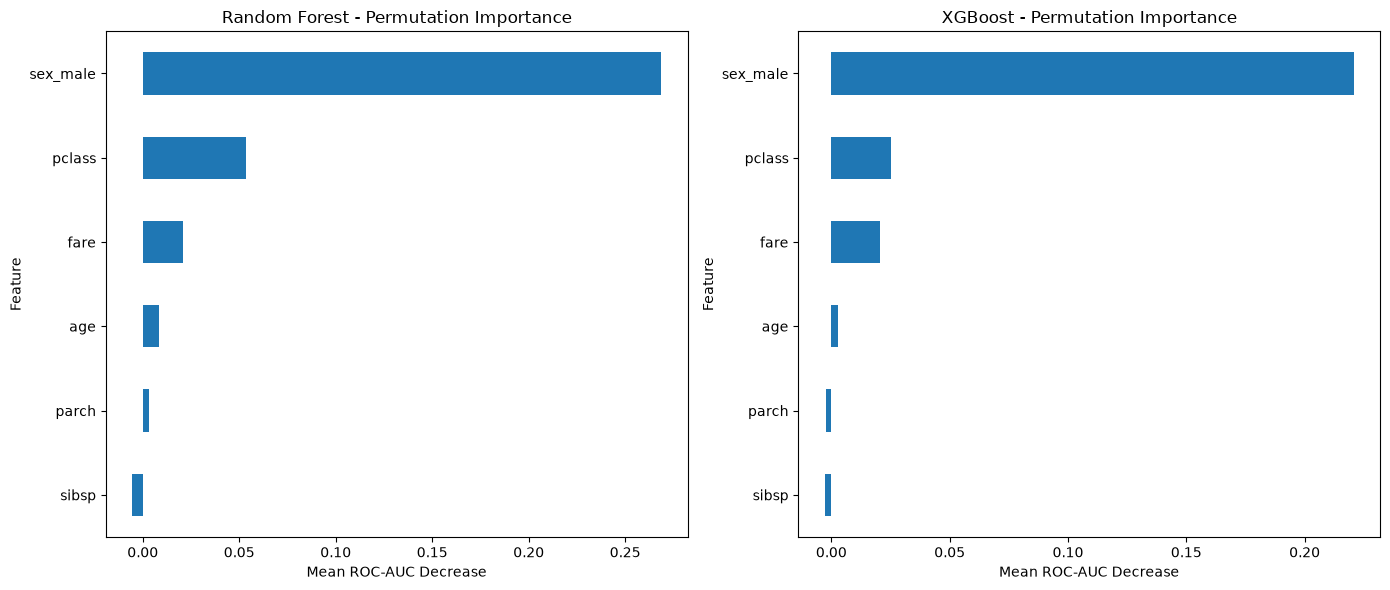

Top feature for PDP: sex_male


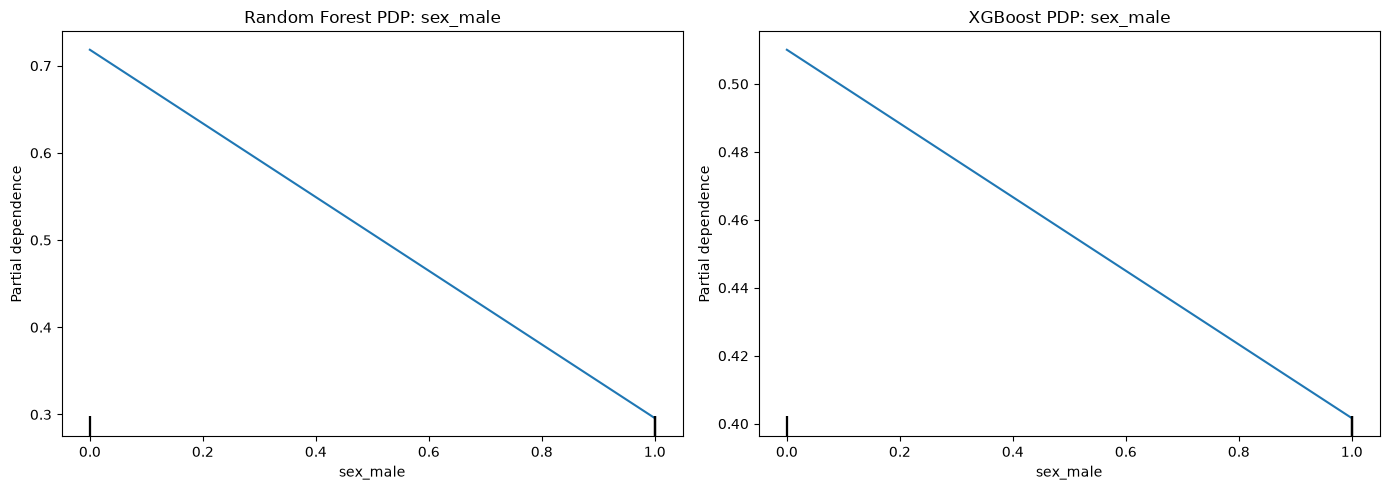

In [14]:

# ==============================================================
# TASK: RANDOM FOREST vs XGBOOST
# PERMUTATION IMPORTANCE + PARTIAL DEPENDENCE PLOTS
# TITANIC DATASET
# ==============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from xgboost import XGBClassifier

# --------------------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------------------

df = pd.read_csv("titanic.csv")

# Clean column names
df.columns = df.columns.str.strip().str.lower()

# Convert sex into numeric feature
if "sex" in df.columns:
    df["sex_male"] = df["sex"].map({"male": 1, "female": 0})

# Select features and target
features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]

X = df[features].copy()
y = df["survived"]

# --------------------------------------------------------------
# 2. TRAIN-TEST SPLIT (SAME TEST SET FOR BOTH MODELS)
# --------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# --------------------------------------------------------------
# 3. HANDLE MISSING VALUES USING TRAINING DATA ONLY
# --------------------------------------------------------------

# Age median based on passenger class and sex
age_medians = X_train.groupby(["pclass", "sex_male"])["age"].median()

# Fill missing age in training data
X_train["age"] = X_train.groupby(
    ["pclass", "sex_male"]
)["age"].transform(lambda col: col.fillna(col.median()))

X_train["age"] = X_train["age"].fillna(X_train["age"].median())

# Fill missing age in test data using training group medians
for index in X_test.index:
    if pd.isna(X_test.loc[index, "age"]):
        group = (
            X_test.loc[index, "pclass"],
            X_test.loc[index, "sex_male"]
        )

        if group in age_medians.index:
            X_test.loc[index, "age"] = age_medians.loc[group]

# Fill remaining missing age with training median
X_test["age"] = X_test["age"].fillna(X_train["age"].median())

# Fill missing fare using training median
fare_median = X_train["fare"].median()

X_train["fare"] = X_train["fare"].fillna(fare_median)
X_test["fare"] = X_test["fare"].fillna(fare_median)

# --------------------------------------------------------------
# 4. TRAIN RANDOM FOREST
# --------------------------------------------------------------

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    random_state=42
)

rf_model.fit(X_train, y_train)

# --------------------------------------------------------------
# 5. TRAIN XGBOOST WITH EARLY STOPPING
# --------------------------------------------------------------

# Create validation data from the training set only
X_train_xgb, X_val_xgb, y_train_xgb, y_val_xgb = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

xgb_model = XGBClassifier(
    n_estimators=1000,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="auc",
    early_stopping_rounds=50
)

xgb_model.fit(
    X_train_xgb,
    y_train_xgb,
    eval_set=[(X_val_xgb, y_val_xgb)],
    verbose=False
)

# --------------------------------------------------------------
# 6. PERMUTATION IMPORTANCE FOR RANDOM FOREST
# --------------------------------------------------------------

rf_perm = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=20,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1
)

rf_importance = pd.Series(
    rf_perm.importances_mean,
    index=features
).sort_values(ascending=False)

# --------------------------------------------------------------
# 7. PERMUTATION IMPORTANCE FOR XGBOOST
# --------------------------------------------------------------

xgb_perm = permutation_importance(
    xgb_model,
    X_test,
    y_test,
    n_repeats=20,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1
)

xgb_importance = pd.Series(
    xgb_perm.importances_mean,
    index=features
).sort_values(ascending=False)

# --------------------------------------------------------------
# 8. DISPLAY RANKINGS SIDE BY SIDE
# --------------------------------------------------------------

comparison = pd.DataFrame({
    "Random Forest Importance": rf_importance,
    "XGBoost Importance": xgb_importance
})

comparison["RF Rank"] = comparison["Random Forest Importance"].rank(
    ascending=False, method="min"
).astype(int)

comparison["XGB Rank"] = comparison["XGBoost Importance"].rank(
    ascending=False, method="min"
).astype(int)

comparison["Rank Difference"] = (
    comparison["RF Rank"] - comparison["XGB Rank"]
).abs()

comparison = comparison.sort_values("RF Rank")

print("\nPERMUTATION IMPORTANCE COMPARISON")
print(comparison.round(4))

# --------------------------------------------------------------
# 9. IDENTIFY FEATURES WITH DIFFERENT RANKINGS
# --------------------------------------------------------------

print("\nFEATURES WITH DIFFERENT RANKINGS")

different_features = comparison.sort_values(
    "Rank Difference", ascending=False
)

print(different_features[
    ["RF Rank", "XGB Rank", "Rank Difference"]
])

# --------------------------------------------------------------
# 10. PLOT PERMUTATION IMPORTANCE SIDE BY SIDE
# --------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

rf_importance.sort_values().plot(
    kind="barh",
    ax=axes[0]
)

axes[0].set_title("Random Forest - Permutation Importance")
axes[0].set_xlabel("Mean ROC-AUC Decrease")
axes[0].set_ylabel("Feature")

xgb_importance.sort_values().plot(
    kind="barh",
    ax=axes[1]
)

axes[1].set_title("XGBoost - Permutation Importance")
axes[1].set_xlabel("Mean ROC-AUC Decrease")
axes[1].set_ylabel("Feature")

plt.tight_layout()
plt.show()


# --------------------------------------------------------------
# 11. SELECT TOP FEATURE
# --------------------------------------------------------------

comparison["Average Rank"] = (
    comparison["RF Rank"] + comparison["XGB Rank"]
) / 2

top_feature = comparison["Average Rank"].idxmin()

print("Top feature for PDP:", top_feature)

# --------------------------------------------------------------
# 12. CONVERT FEATURES TO FLOAT FOR PDP
# --------------------------------------------------------------

# Fix the integer dtype error in newer sklearn versions
X_pdp = X_train.astype(float)

# --------------------------------------------------------------
# 13. PARTIAL DEPENDENCE PLOTS - BOTH MODELS
# --------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Random Forest PDP
PartialDependenceDisplay.from_estimator(
    rf_model,
    X_pdp,
    features=[top_feature],
    kind="average",
    grid_resolution=20,
    ax=axes[0]
)

axes[0].set_title(f"Random Forest PDP: {top_feature}")

# XGBoost PDP
PartialDependenceDisplay.from_estimator(
    xgb_model,
    X_pdp,
    features=[top_feature],
    kind="average",
    grid_resolution=20,
    ax=axes[1]
)

axes[1].set_title(f"XGBoost PDP: {top_feature}")

plt.tight_layout()
plt.show()


**1. If two model families agree on important features:**\
It suggests the features have a strong, consistent relationship with the target, and the pattern is not specific to one model's learning method. This increases confidence in the finding.

**2. If two model families disagree sharply:**\
I would investigate feature interactions, correlations between features, overfitting, data quality, and differences in how the models learn patterns before trusting either model's interpretation.

## Part E — Intern-style delivery

## TASK 11 — Write a model selection memo

# Model Recommendation Memo – Titanic Survival Prediction

**1. Recommended Model**

I recommend **XGBoost** because early stopping helps control overfitting by selecting the appropriate number of trees based on validation performance.

**2. Model Performance**

| Metric | Random Forest | XGBoost |
|---|---|---|
| Test ROC-AUC | [0.8781] | [0.8576] |
| Train ROC-AUC | [0.8811] | [0.8379] |
| Train-Test Gap | [0.003] | [-0.0197] |

**3. Recommended Model Hyperparameters**

XGBoost:
- n_estimators = 1000
- max_depth = 3
- learning_rate = 0.05
- subsample = 0.8
- colsample_bytree = 0.8
- random_state = 42
- eval_metric = 'auc'
- early_stopping_rounds = 50

The tree count was decided using early stopping, which stops training when validation performance does not improve for 50 consecutive rounds. The selected tree count is based on `best_iteration + 1`.

**4. Risk**

XGBoost can still overfit or learn misleading patterns, especially with limited training data. Its performance may also vary with different data splits.

**5. Next Experiment**

I would test different hyperparameters using cross-validation to check whether the model's performance is stable across different data splits.

**6. Important Features**

The important features include sex_male, pclass, age and fare. Both Random Forest and XGBoost should be compared using permutation importance to check whether they agree on the most important features. Agreement would increase confidence in the findings.

**Final Recommendation:** XGBoost is my preferred model because of its early-stopping mechanism and ability to capture complex patterns. Its final selection should also be supported by its test ROC-AUC and train-test gap.

In [15]:
from sklearn.metrics import roc_auc_score

for name, model in [
    ("Random Forest", rf_model),
    ("XGBoost", xgb_model)
]:
    train_auc = roc_auc_score(
        y_train, model.predict_proba(X_train)[:, 1]
    )

    test_auc = roc_auc_score(
        y_test, model.predict_proba(X_test)[:, 1]
    )

    print(name)
    print("Train ROC-AUC:", round(train_auc, 4))
    print("Test ROC-AUC:", round(test_auc, 4))
    print("Train-Test Gap:", round(train_auc - test_auc, 4))

Random Forest
Train ROC-AUC: 0.8811
Test ROC-AUC: 0.8781
Train-Test Gap: 0.003
XGBoost
Train ROC-AUC: 0.8379
Test ROC-AUC: 0.8576
Train-Test Gap: -0.0197
